# CS 463 Project — Modeling

**Task:** on the order date, forecast each product's daily unit sales
`HORIZON = 7` days ahead for store CA_1 (see `02_Data_Preparation.ipynb`).

**Model progression** (from the Update 2 plan, plus a custom model):

1. Naive baselines
2. Linear Regression, Ridge, LASSO
3. Random Forest
4. XGBoost (squared-error loss and Tweedie loss)
5. **Two-stage hurdle model** — custom model for intermittent demand

Every trained model is saved to the `models/` folder, and every model's
validation predictions are saved to `validation_predictions.parquet`, so
Update 4 can evaluate on the test set without retraining.

**Evaluation rules**

- Models train on the training period, excluding suspected-stockout rows.
- Hyperparameters are chosen on the **validation** set.
- Early stopping uses the **last 10% of training dates**, never the
  validation set, so validation scores are not optimistic.
- The **test** set is not used in this notebook; it is reserved for the final
  evaluation in Update 4.
- Every model is scored on all validation rows and on non-stockout rows. We
  also report **bias** — how far the average forecast is above (+) or below (−)
  average actual demand — because a forecast that runs low leaves shelves empty.

In [1]:
import json
import os
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    accuracy_score,
    f1_score,
)

import xgboost as xgb

SEED = 42
HORIZON = 7

np.random.seed(SEED)
os.makedirs("models", exist_ok=True)

# Feature list is written by 02_Data_Preparation.ipynb
with open("feature_columns.json") as f:
    feature_columns = json.load(f)

# Load only the columns the models need, to save memory
id_columns = ["item_id", "cat_id", "date", "target_sales", "is_suspected_stockout"]

train = pd.read_parquet("train.parquet", columns=id_columns + feature_columns)
validation = pd.read_parquet("validation.parquet", columns=id_columns + feature_columns)

print("Train:", train.shape)
print("Validation:", validation.shape)
print(len(feature_columns), "features")

Train: (2885839, 52)
Validation: (842328, 52)
47 features


In [2]:
# Train only on rows that are not suspected stockouts, so the model learns
# customer demand rather than shelf availability
train_clean = train[train["is_suspected_stockout"] == 0].reset_index(drop=True)

print(
    "Training rows:", f"{len(train_clean):,}",
    f"({len(train) - len(train_clean):,} suspected-stockout rows excluded)"
)

# Last 10% of training dates: used only for early stopping
es_cutoff = train_clean["date"].quantile(0.9)
fit_part = train_clean[train_clean["date"] < es_cutoff].reset_index(drop=True)
es_part = train_clean[train_clean["date"] >= es_cutoff].reset_index(drop=True)

print("Fit part:", fit_part["date"].min().date(), "to", fit_part["date"].max().date())
print("Early-stopping part:", es_part["date"].min().date(), "to", es_part["date"].max().date())

X_train = train_clean[feature_columns]
y_train = train_clean["target_sales"]

X_val = validation[feature_columns]
y_val = validation["target_sales"].to_numpy()
val_not_stockout = (validation["is_suspected_stockout"] == 0).to_numpy()

Training rows: 2,372,778 (513,061 suspected-stockout rows excluded)


Fit part: 2011-03-04 to 2014-06-29
Early-stopping part: 2014-06-30 to 2014-10-07


In [3]:
results = []
val_predictions = validation[["item_id", "cat_id", "date", "target_sales", "is_suspected_stockout"]].copy()


def report(name, y_pred, train_seconds=None):
    """Scores a model on the validation set and adds it to the results."""
    y_pred = np.maximum(0, np.asarray(y_pred, dtype=float))
    mask = val_not_stockout
    val_predictions[name] = y_pred.astype(np.float32)

    row = {
        "model": name,
        "MAE (all rows)": mean_absolute_error(y_val, y_pred),
        "MAE (non-stockout)": mean_absolute_error(y_val[mask], y_pred[mask]),
        "RMSE (all rows)": np.sqrt(mean_squared_error(y_val, y_pred)),
        "RMSE (non-stockout)": np.sqrt(mean_squared_error(y_val[mask], y_pred[mask])),
        "Bias (non-stockout)": y_pred[mask].mean() / y_val[mask].mean() - 1,
        "Train time (s)": train_seconds,
    }

    results.append(row)
    return pd.DataFrame([row]).round(3)

## 1. Naive baselines

Every model must beat these.

- **Sales 7 days earlier**: the most recent sales known on the order date
- **28-day average**: average daily sales over the 28 days ending on the
  order date

In [4]:
report("Baseline: sales 7 days earlier", validation["sales_lag_7"])
report("Baseline: 28-day average", validation["rolling_mean_28"])

pd.DataFrame(results).round(3)

,model,MAE (all rows),MAE (non-stockout),RMSE (all rows),RMSE (non-stockout),Bias (non-stockout),Train time (s)
0,Baseline: sales 7 days earlier,1.289,1.437,2.967,3.022,-0.055,None
1,Baseline: 28-day average,1.128,1.185,2.551,2.527,-0.093,None


## 2. Linear models

Features are standardized first, so the Ridge and LASSO penalties treat
every feature equally.

| Model | Loss | Hyperparameter |
|---|---|---|
| Linear Regression | Mean squared error | — |
| Ridge | MSE + α·‖w‖² (L2) | α chosen on validation |
| LASSO | MSE + α·‖w‖₁ (L1) | α chosen on validation |

LASSO's L1 penalty pushes unhelpful feature weights to exactly zero, which
shows which features matter.

In [5]:
start = time.time()

linear_model = make_pipeline(StandardScaler(), LinearRegression())
linear_model.fit(X_train, y_train)

report("Linear Regression", linear_model.predict(X_val), time.time() - start)

,model,MAE (all rows),MAE (non-stockout),RMSE (all rows),RMSE (non-stockout),Bias (non-stockout),Train time (s)
0,Linear Regression,1.159,1.203,2.428,2.408,0.017,2.572


In [6]:
def tune(make_model, values, name):
    """Fits one model per hyperparameter value and keeps the best on validation."""
    scores = {}
    models = {}

    for value in values:
        model = make_model(value)
        model.fit(X_train, y_train)
        pred = np.maximum(0, model.predict(X_val))
        scores[value] = mean_absolute_error(y_val[val_not_stockout], pred[val_not_stockout])
        models[value] = model
        print(f"{name} = {value}: validation MAE (non-stockout) = {scores[value]:.4f}")

    best = min(scores, key=scores.get)
    print("Best:", best)
    return best, models[best]


start = time.time()
best_ridge_alpha, ridge_model = tune(
    lambda a: make_pipeline(StandardScaler(), Ridge(alpha=a)),
    [0.1, 10, 1000, 10000],
    "alpha"
)
report(f"Ridge (alpha={best_ridge_alpha})", ridge_model.predict(X_val), time.time() - start)

alpha = 0.1: validation MAE (non-stockout) = 1.2031


alpha = 10: validation MAE (non-stockout) = 1.2031


alpha = 1000: validation MAE (non-stockout) = 1.2031


alpha = 10000: validation MAE (non-stockout) = 1.2034
Best: 0.1


,model,MAE (all rows),MAE (non-stockout),RMSE (all rows),RMSE (non-stockout),Bias (non-stockout),Train time (s)
0,Ridge (alpha=0.1),1.159,1.203,2.428,2.408,0.017,16.772


In [7]:
start = time.time()
best_lasso_alpha, lasso_model = tune(
    lambda a: make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=2000)),
    [0.001, 0.01, 0.1],
    "alpha"
)
report(f"LASSO (alpha={best_lasso_alpha})", lasso_model.predict(X_val), time.time() - start)

alpha = 0.001: validation MAE (non-stockout) = 1.2030


alpha = 0.01: validation MAE (non-stockout) = 1.2028


alpha = 0.1: validation MAE (non-stockout) = 1.2153
Best: 0.01


,model,MAE (all rows),MAE (non-stockout),RMSE (all rows),RMSE (non-stockout),Bias (non-stockout),Train time (s)
0,LASSO (alpha=0.01),1.158,1.203,2.427,2.408,0.016,15.517


Features LASSO set to zero: ['month_2', 'month_4', 'cat_HOBBIES', 'event_type_Religious', 'month_3', 'month_5', 'is_event_day', 'month_6', 'month_7', 'wday_3', 'price_change', 'month_9', 'dept_FOODS_1', 'dept_FOODS_2', 'dept_HOBBIES_1', 'dept_HOUSEHOLD_1', 'cat_FOODS', 'wday_1']


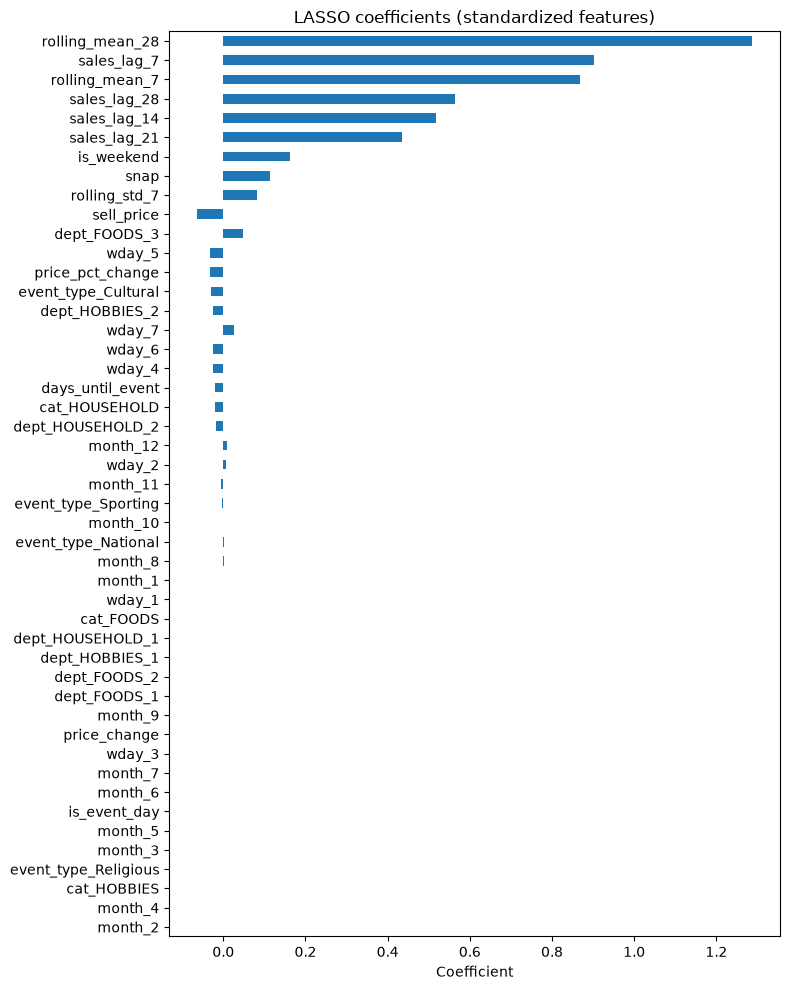

In [8]:
lasso_coefs = pd.Series(
    lasso_model[-1].coef_,
    index=feature_columns
).sort_values(key=abs)

print("Features LASSO set to zero:", list(lasso_coefs[lasso_coefs == 0].index))

plt.figure(figsize=(8, 10))
lasso_coefs.plot(kind="barh")
plt.title("LASSO coefficients (standardized features)")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

## 3. Random Forest

An ensemble of decision trees, each trained on a bootstrap sample of rows,
with predictions averaged. Random Forest is slow on millions of rows, so it is
trained on a random sample of 400,000 training rows.

| Hyperparameter | Value |
|---|---|
| Loss (split criterion) | Squared error |
| Trees | 100 |
| Max depth | 14 |
| Min samples per leaf | 20 |
| Features per split | 50% |
| Training rows | 400,000 (random sample) |

In [9]:
rf_sample = train_clean.sample(400_000, random_state=SEED)

start = time.time()

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=14,
    min_samples_leaf=20,
    max_features=0.5,
    n_jobs=-1,
    random_state=SEED
)
rf_model.fit(rf_sample[feature_columns], rf_sample["target_sales"])

report("Random Forest", rf_model.predict(X_val), time.time() - start)

del rf_sample

### 3.1 Cross-validation for the Random Forest

The Random Forest above is scored once, on a single validation period.
Cross-validation trains and scores it several times on different splits of
the **training** data, which shows how stable its score is. We compare two
kinds:

1. **k-fold (`KFold`)** — rows are shuffled into 5 random folds. This is the
   textbook method, but it is **not suitable for time series**: each model is
   trained on days *after* the days it is scored on, so it can learn from the
   future.
2. **Time-series (`TimeSeriesSplit`)** — the training period is cut into 5
   folds **by date**. Each fold trains only on earlier dates and is scored on
   the period right after, exactly like a real forecast.

Same hyperparameters as above. Each fold trains on at most 400,000 rows. The
validation and test sets are not used.

**Note:** the folds are scored on 2011–2014, when products sold more per day
on average than in the validation period (1.75 vs. 1.46 units), so the CV
errors are larger than the validation errors. Compare k-fold with
time-series CV directly, not with the validation table.

In [10]:
from sklearn.model_selection import KFold, TimeSeriesSplit

MAX_TRAIN_ROWS = 400_000
N_FOLDS = 5

cv_data = train_clean.sort_values("date").reset_index(drop=True)


def make_forest():
    # Same hyperparameters as the Random Forest above
    return RandomForestRegressor(
        n_estimators=100,
        max_depth=14,
        min_samples_leaf=20,
        max_features=0.5,
        n_jobs=-1,
        random_state=SEED
    )


def run_fold(method, fold, train_rows, score_rows):
    """Trains on train_rows (sampled down to MAX_TRAIN_ROWS) and scores on score_rows."""
    rng = np.random.default_rng(SEED + fold)
    if len(train_rows) > MAX_TRAIN_ROWS:
        train_rows = rng.choice(train_rows, MAX_TRAIN_ROWS, replace=False)

    fit_data = cv_data.iloc[train_rows]
    score_data = cv_data.iloc[score_rows]

    model = make_forest()
    model.fit(fit_data[feature_columns], fit_data["target_sales"])
    pred = np.maximum(0, model.predict(score_data[feature_columns]))

    y = score_data["target_sales"].to_numpy()

    return {
        "method": method,
        "fold": fold,
        "train from": fit_data["date"].min().date(),
        "train to": fit_data["date"].max().date(),
        "score from": score_data["date"].min().date(),
        "score to": score_data["date"].max().date(),
        "train rows": len(fit_data),
        "score rows": len(score_data),
        "MAE": mean_absolute_error(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "Bias": pred.mean() / y.mean() - 1,
    }


cv_results = []

**k-fold:** rows are shuffled, then split into 5 equal folds. Each fold is
scored by a model trained on the other 4 folds — which contain days both
before *and after* the scored days. To keep this fast, it runs on a random
sample of 500,000 clean training rows (400,000 train / 100,000 score per fold).

In [11]:
kfold_sample = np.random.default_rng(SEED).choice(len(cv_data), 500_000, replace=False)

kfold = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

for fold, (train_idx, score_idx) in enumerate(kfold.split(kfold_sample), start=1):
    row = run_fold("KFold", fold, kfold_sample[train_idx], kfold_sample[score_idx])
    cv_results.append(row)
    print(f"KFold fold {fold}: MAE = {row['MAE']:.3f}, RMSE = {row['RMSE']:.3f}")

KFold fold 1: MAE = 1.349, RMSE = 2.935


KFold fold 2: MAE = 1.324, RMSE = 2.930


KFold fold 3: MAE = 1.340, RMSE = 2.940


KFold fold 4: MAE = 1.333, RMSE = 2.851


KFold fold 5: MAE = 1.332, RMSE = 2.825


**Time-series:** `TimeSeriesSplit` is applied to the list of unique **dates**,
not rows, so all rows from one day stay in the same fold. Each fold trains on
all dates before its scoring period (an *expanding window*):

```
fold 1:  [train]                 [score]
fold 2:  [train   train]                 [score]
fold 3:  [train   train   train]                 [score]
...
```

In [12]:
unique_dates = np.sort(cv_data["date"].unique())
row_dates = cv_data["date"].to_numpy()

time_split = TimeSeriesSplit(n_splits=N_FOLDS)

for fold, (train_date_idx, score_date_idx) in enumerate(time_split.split(unique_dates), start=1):
    train_rows = np.flatnonzero(np.isin(row_dates, unique_dates[train_date_idx]))
    score_rows = np.flatnonzero(np.isin(row_dates, unique_dates[score_date_idx]))

    row = run_fold("TimeSeriesSplit", fold, train_rows, score_rows)
    cv_results.append(row)
    print(
        f"TimeSeriesSplit fold {fold}: train {row['train from']} to {row['train to']}, "
        f"score {row['score from']} to {row['score to']}: "
        f"MAE = {row['MAE']:.3f}, RMSE = {row['RMSE']:.3f}"
    )

TimeSeriesSplit fold 1: train 2011-03-04 to 2011-10-10, score 2011-10-11 to 2012-05-16: MAE = 1.460, RMSE = 3.325


TimeSeriesSplit fold 2: train 2011-03-04 to 2012-05-16, score 2012-05-17 to 2012-12-20: MAE = 1.356, RMSE = 3.159


TimeSeriesSplit fold 3: train 2011-03-04 to 2012-12-20, score 2012-12-21 to 2013-07-27: MAE = 1.324, RMSE = 2.761


TimeSeriesSplit fold 4: train 2011-03-04 to 2013-07-27, score 2013-07-28 to 2014-03-03: MAE = 1.328, RMSE = 3.171


TimeSeriesSplit fold 5: train 2011-03-04 to 2014-03-03, score 2014-03-04 to 2014-10-07: MAE = 1.234, RMSE = 2.528


In [13]:
cv_table = pd.DataFrame(cv_results)
cv_table.to_csv("rf_cross_validation.csv", index=False)

cv_summary = cv_table.groupby("method")[["MAE", "RMSE", "Bias"]].agg(["mean", "std"])

print("Fold-by-fold results:")
display(cv_table.style.format({
    "MAE": "{:.3f}", "RMSE": "{:.3f}", "Bias": "{:+.1%}",
    "train rows": "{:,}", "score rows": "{:,}",
}))

print("Mean and standard deviation across folds:")
cv_summary.style.format("{:.3f}")

Fold-by-fold results:


,method,fold,train from,train to,score from,score to,train rows,score rows,MAE,RMSE,Bias
0,KFold,1,2011-03-04,2014-10-07,2011-03-04,2014-10-07,"400,000","100,000",1.349,2.935,-0.2%
1,KFold,2,2011-03-04,2014-10-07,2011-03-04,2014-10-07,"400,000","100,000",1.324,2.930,-0.1%
2,KFold,3,2011-03-04,2014-10-07,2011-03-04,2014-10-07,"400,000","100,000",1.340,2.940,-0.3%
3,KFold,4,2011-03-04,2014-10-07,2011-03-04,2014-10-07,"400,000","100,000",1.333,2.851,+0.2%
4,KFold,5,2011-03-04,2014-10-07,2011-03-04,2014-10-07,"400,000","100,000",1.332,2.825,+0.3%
5,TimeSeriesSplit,1,2011-03-04,2011-10-10,2011-10-11,2012-05-16,"283,724","330,542",1.460,3.325,-0.0%
6,TimeSeriesSplit,2,2011-03-04,2012-05-16,2012-05-17,2012-12-20,"400,000","382,744",1.356,3.159,+2.4%
7,TimeSeriesSplit,3,2011-03-04,2012-12-20,2012-12-21,2013-07-27,"400,000","417,934",1.324,2.761,-0.5%
8,TimeSeriesSplit,4,2011-03-04,2013-07-27,2013-07-28,2014-03-03,"400,000","453,464",1.328,3.171,+0.3%
9,TimeSeriesSplit,5,2011-03-04,2014-03-03,2014-03-04,2014-10-07,"400,000","504,370",1.234,2.528,-0.3%


Mean and standard deviation across folds:


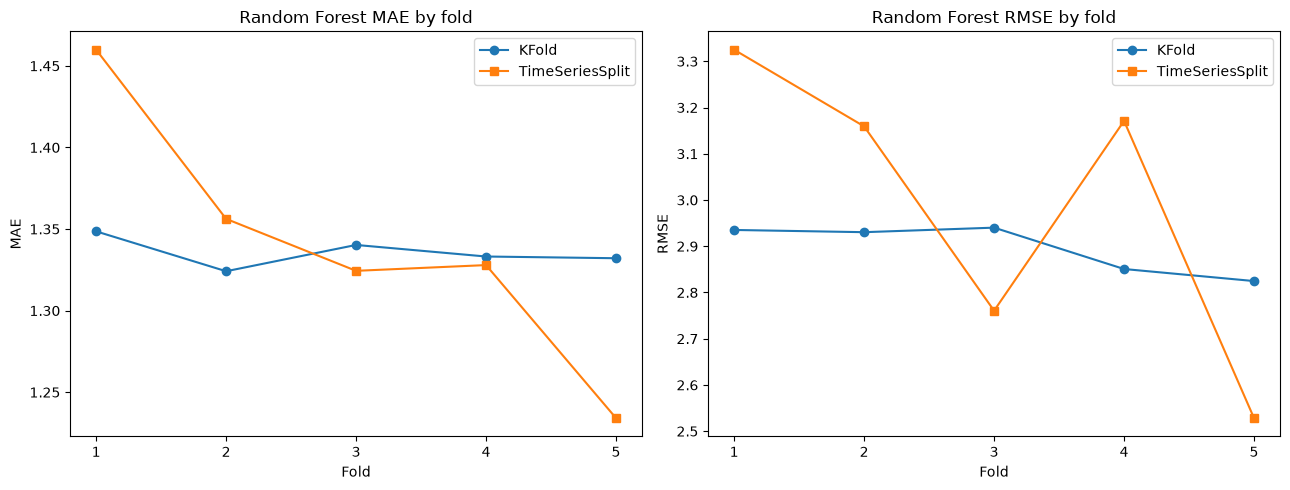

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for method, marker in [("KFold", "o"), ("TimeSeriesSplit", "s")]:
    rows = cv_table[cv_table["method"] == method]
    axes[0].plot(rows["fold"], rows["MAE"], marker=marker, label=method)
    axes[1].plot(rows["fold"], rows["RMSE"], marker=marker, label=method)

for ax, metric in zip(axes, ["MAE", "RMSE"]):
    ax.set_title(f"Random Forest {metric} by fold")
    ax.set_xlabel("Fold")
    ax.set_ylabel(metric)
    ax.set_xticks(range(1, N_FOLDS + 1))
    ax.legend()

plt.tight_layout()
plt.show()

**How to read this:**

- **k-fold vs. time-series average:** if k-fold's error is lower, it is too
  optimistic, because its models were trained on days after the ones they
  were scored on — impossible in real forecasting.
- **Spread (standard deviation):** k-fold mixes all periods in every fold, so
  its scores barely change and hide how much accuracy varies over time.
  Time-series CV shows that variation honestly.
- **Time-series folds over time:** later folds train on more history, so
  their error may be lower.

## 4. XGBoost

Gradient-boosted trees: each new tree corrects the errors of the trees before
it. We compare two loss functions:

- **Squared error** — the standard regression loss.
- **Tweedie** — designed for non-negative targets with many exact zeros and a
  long right tail, which matches daily product sales. The variance power `p`
  (between 1 = Poisson and 2 = Gamma) is chosen on validation.

| Hyperparameter | Value |
|---|---|
| Learning rate | 0.05 |
| Max depth | 8 |
| Min child weight | 10 |
| Row / column subsample | 0.8 / 0.8 |
| Max trees | 2,000, with early stopping after 50 rounds without improvement |
| Tree method | `hist` |

In [15]:
xgb_params = dict(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=8,
    min_child_weight=10,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    early_stopping_rounds=50,
    n_jobs=-1,
    random_state=SEED,
)

X_fit, y_fit = fit_part[feature_columns], fit_part["target_sales"]
X_es, y_es = es_part[feature_columns], es_part["target_sales"]


def fit_xgb(**params):
    model = xgb.XGBRegressor(**xgb_params, **params)
    model.fit(X_fit, y_fit, eval_set=[(X_es, y_es)], verbose=False)
    return model


start = time.time()
xgb_mse = fit_xgb(objective="reg:squarederror")
print("Trees used:", xgb_mse.best_iteration + 1)
report("XGBoost (squared error)", xgb_mse.predict(X_val), time.time() - start)

Trees used: 106


,model,MAE (all rows),MAE (non-stockout),RMSE (all rows),RMSE (non-stockout),Bias (non-stockout),Train time (s)
0,XGBoost (squared error),1.211,1.175,2.556,2.292,0.012,6.746


In [16]:
tweedie_scores = {}
tweedie_models = {}
tweedie_times = {}

for power in [1.1, 1.3, 1.5]:
    start = time.time()
    model = fit_xgb(objective="reg:tweedie", tweedie_variance_power=power)
    tweedie_times[power] = time.time() - start

    pred = model.predict(X_val)
    tweedie_scores[power] = mean_absolute_error(
        y_val[val_not_stockout], pred[val_not_stockout]
    )
    tweedie_models[power] = model
    print(
        f"Tweedie power {power}: validation MAE (non-stockout) = "
        f"{tweedie_scores[power]:.4f}, trees used = {model.best_iteration + 1}"
    )

best_power = min(tweedie_scores, key=tweedie_scores.get)
xgb_tweedie = tweedie_models[best_power]

report(
    f"XGBoost (Tweedie, p={best_power})",
    xgb_tweedie.predict(X_val),
    tweedie_times[best_power]
)

Tweedie power 1.1: validation MAE (non-stockout) = 1.1603, trees used = 444


Tweedie power 1.3: validation MAE (non-stockout) = 1.1581, trees used = 390


Tweedie power 1.5: validation MAE (non-stockout) = 1.1573, trees used = 291


,model,MAE (all rows),MAE (non-stockout),RMSE (all rows),RMSE (non-stockout),Bias (non-stockout),Train time (s)
0,"XGBoost (Tweedie, p=1.5)",1.195,1.157,2.472,2.27,-0.001,16.831


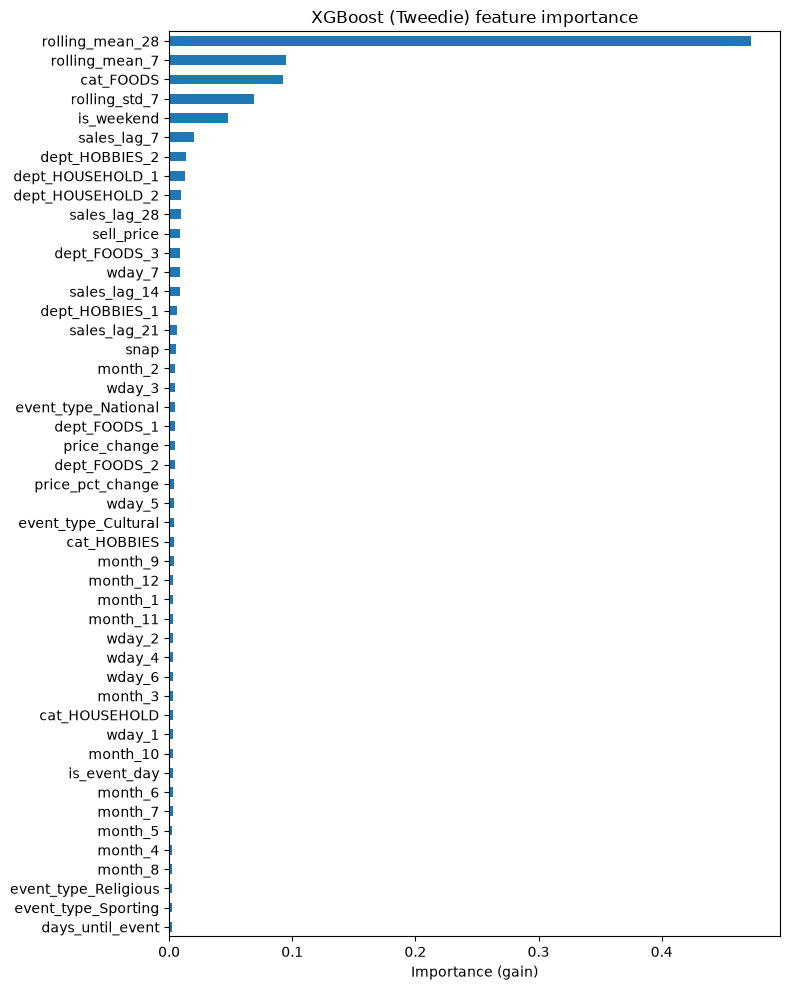

In [17]:
importance = pd.Series(
    xgb_tweedie.feature_importances_,
    index=feature_columns
).sort_values()

plt.figure(figsize=(8, 10))
importance.plot(kind="barh")
plt.title("XGBoost (Tweedie) feature importance")
plt.xlabel("Importance (gain)")
plt.tight_layout()
plt.show()

## 5. Two-stage hurdle model (custom model)

More than half of all product-days have zero sales. A single regression model
has to explain both *whether* a product sells and *how much* it sells. The
hurdle model splits these into two stages:

1. **Stage 1 — classifier:** probability the product sells at least one unit,
   `P(sales > 0)`. Trained on all clean training rows.
   Loss: binary cross-entropy (log loss).
2. **Stage 2 — regressor:** expected sales *given* the product sells.
   Trained only on rows with sales > 0. Because those sales are at least 1,
   it predicts `sales − 1` with a Poisson loss, so the result is always ≥ 1.

**Forecast = P(sales > 0) × (1 + predicted extra units)**

Both stages use XGBoost with the same hyperparameters as Section 4.
Stage 1 also answers the secondary task from Update 2: classifying whether a
product will sell on a given day.

In [18]:
start = time.time()

# Stage 1: will the product sell at all?
hurdle_classifier = xgb.XGBClassifier(
    **xgb_params,
    objective="binary:logistic",
    eval_metric="logloss"
)
hurdle_classifier.fit(
    X_fit, (y_fit > 0).astype(int),
    eval_set=[(X_es, (y_es > 0).astype(int))],
    verbose=False
)

# Stage 2: how many units, given that it sells?
fit_pos = fit_part[fit_part["target_sales"] > 0]
es_pos = es_part[es_part["target_sales"] > 0]

hurdle_regressor = xgb.XGBRegressor(**xgb_params, objective="count:poisson")
hurdle_regressor.fit(
    fit_pos[feature_columns], fit_pos["target_sales"] - 1,
    eval_set=[(es_pos[feature_columns], es_pos["target_sales"] - 1)],
    verbose=False
)

hurdle_seconds = time.time() - start

print("Stage 1 trees used:", hurdle_classifier.best_iteration + 1)
print("Stage 2 trees used:", hurdle_regressor.best_iteration + 1)

Stage 1 trees used: 434
Stage 2 trees used: 601


In [19]:
prob_sells = hurdle_classifier.predict_proba(X_val)[:, 1]
units_if_sells = 1 + hurdle_regressor.predict(X_val)

hurdle_prediction = prob_sells * units_if_sells

report("Hurdle model (XGBoost + XGBoost)", hurdle_prediction, hurdle_seconds)

,model,MAE (all rows),MAE (non-stockout),RMSE (all rows),RMSE (non-stockout),Bias (non-stockout),Train time (s)
0,Hurdle model (XGBoost + XGBoost),1.209,1.16,2.484,2.263,0.005,40.463


In [20]:
# Stage 1 as a classifier: will the product sell on this day?
sells_val = (y_val > 0).astype(int)
sells_pred = (prob_sells >= 0.5).astype(int)

print("Stage 1 classification (validation):")
print(f"  Share of days with a sale: {sells_val.mean():.1%}")
print(f"  ROC AUC:  {roc_auc_score(sells_val, prob_sells):.3f}")
print(f"  Accuracy: {accuracy_score(sells_val, sells_pred):.3f}")
print(f"  F1 score: {f1_score(sells_val, sells_pred):.3f}")

# Check of stage 2 on days that actually had sales
pos = y_val > 0
print("Stage 2 on days with sales:")
print(f"  MAE: {mean_absolute_error(y_val[pos], units_if_sells[pos]):.3f}")

Stage 1 classification (validation):
  Share of days with a sale: 43.8%
  ROC AUC:  0.792
  Accuracy: 0.719


  F1 score: 0.692
Stage 2 on days with sales:
  MAE: 1.517


## 6. Save models and results

| File | Model |
|---|---|
| `models/linear_regression.joblib` | Linear Regression (with scaler) |
| `models/ridge.joblib` | Ridge (with scaler) |
| `models/lasso.joblib` | LASSO (with scaler) |
| `models/random_forest.joblib` | Random Forest |
| `models/xgb_squared_error.json` | XGBoost, squared error |
| `models/xgb_tweedie.json` | XGBoost, Tweedie |
| `models/hurdle_classifier.json` | Hurdle stage 1 |
| `models/hurdle_regressor.json` | Hurdle stage 2 |

To reload, for example:
`joblib.load("models/ridge.joblib")` or
`model = xgb.XGBRegressor(); model.load_model("models/xgb_tweedie.json")`.

In [25]:
joblib.dump(linear_model, "models/linear_regression.joblib")
joblib.dump(ridge_model, "models/ridge.joblib")
joblib.dump(lasso_model, "models/lasso.joblib")
joblib.dump(rf_model, "models/random_forest.joblib", compress=3)

xgb_mse.save_model("models/xgb_squared_error.json")
xgb_tweedie.save_model("models/xgb_tweedie.json")
hurdle_classifier.save_model("models/hurdle_classifier.json")
hurdle_regressor.save_model("models/hurdle_regressor.json")

results_table = pd.DataFrame(results)

# Keep results and predictions that other notebooks added (e.g. neural networks)
if os.path.exists("model_results_validation.csv"):
    other_results = pd.read_csv("model_results_validation.csv")
    other_results = other_results[~other_results["model"].isin(results_table["model"])]
    pd.concat([results_table, other_results]).to_csv("model_results_validation.csv", index=False)
else:
    results_table.to_csv("model_results_validation.csv", index=False)

if os.path.exists("validation_predictions.parquet"):
    other_predictions = pd.read_parquet("validation_predictions.parquet")
    for column in other_predictions.columns.difference(val_predictions.columns):
        val_predictions[column] = other_predictions[column].to_numpy()

val_predictions.to_parquet("validation_predictions.parquet", index=False)

for file in sorted(os.listdir("models")):
    size_mb = os.path.getsize(os.path.join("models", file)) / 1e6
    print(f"{file:32s} {size_mb:8.1f} MB")

.ipynb_checkpoints                    0.0 MB
hurdle_classifier.json                7.5 MB
hurdle_regressor.json                16.2 MB
lasso.joblib                          0.0 MB
linear_regression.joblib              0.0 MB
lstm.pt                               0.3 MB
mlp.pt                                0.3 MB
nn_preprocessing.joblib               0.1 MB
random_forest.joblib                  8.9 MB
ridge.joblib                          0.0 MB
xgb_squared_error.json                1.7 MB
xgb_tweedie.json                      8.2 MB


## 7. Results on the validation set

Lower MAE and RMSE are better. Bias near 0% is better: negative bias means the
model under-forecasts demand, which leads to stockouts.

In [26]:
results_table.sort_values("MAE (non-stockout)").style.format({
    "MAE (all rows)": "{:.3f}",
    "MAE (non-stockout)": "{:.3f}",
    "RMSE (all rows)": "{:.3f}",
    "RMSE (non-stockout)": "{:.3f}",
    "Bias (non-stockout)": "{:+.1%}",
    "Train time (s)": "{:.0f}",
}, na_rep="—")

,model,MAE (all rows),MAE (non-stockout),RMSE (all rows),RMSE (non-stockout),Bias (non-stockout),Train time (s)
7,"XGBoost (Tweedie, p=1.5)",1.195,1.157,2.472,2.270,-0.1%,17
8,Hurdle model (XGBoost + XGBoost),1.209,1.160,2.484,2.263,+0.5%,40
6,XGBoost (squared error),1.211,1.175,2.556,2.292,+1.2%,7
5,Random Forest,1.212,1.176,2.437,2.322,+1.0%,11
1,Baseline: 28-day average,1.128,1.185,2.551,2.527,-9.3%,—
4,LASSO (alpha=0.01),1.158,1.203,2.427,2.408,+1.6%,16
2,Linear Regression,1.159,1.203,2.428,2.408,+1.7%,3
3,Ridge (alpha=0.1),1.159,1.203,2.428,2.408,+1.7%,17
0,Baseline: sales 7 days earlier,1.289,1.437,2.967,3.022,-5.5%,—


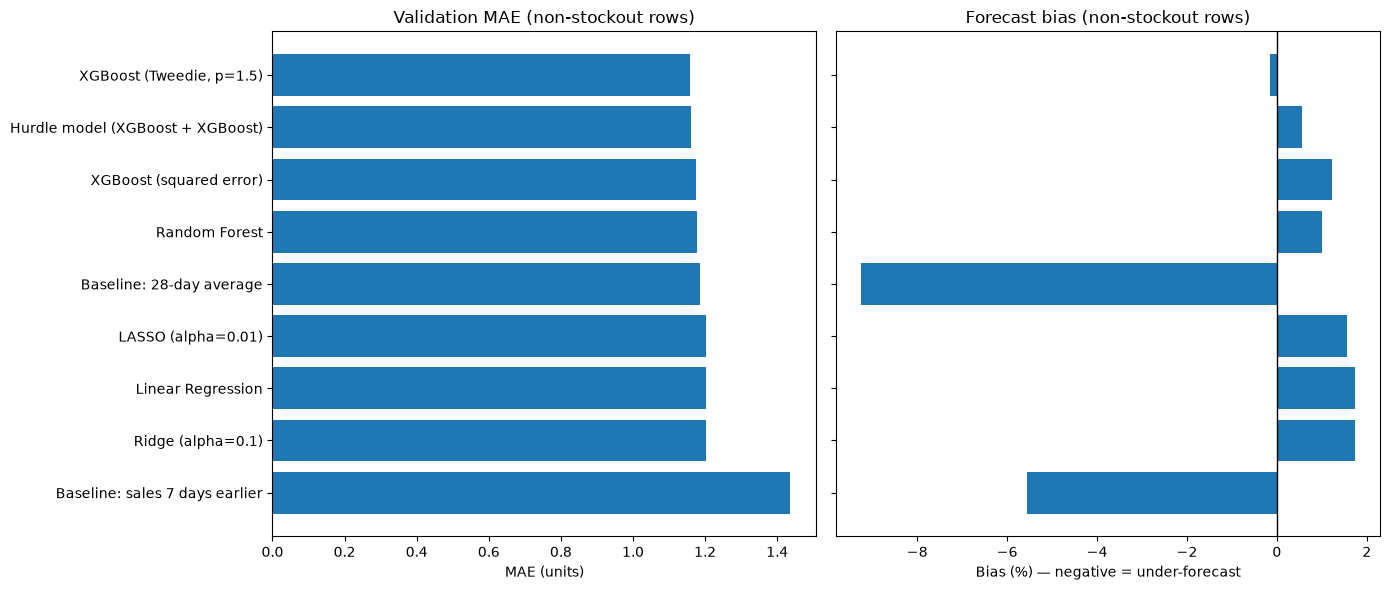

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

ordered = results_table.sort_values("MAE (non-stockout)", ascending=False)

axes[0].barh(ordered["model"], ordered["MAE (non-stockout)"])
axes[0].set_title("Validation MAE (non-stockout rows)")
axes[0].set_xlabel("MAE (units)")

axes[1].barh(ordered["model"], ordered["Bias (non-stockout)"] * 100)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Forecast bias (non-stockout rows)")
axes[1].set_xlabel("Bias (%) — negative = under-forecast")

plt.tight_layout()
plt.show()